# Can pitch data help predict Phillies pitcher strikeouts?

This notebook gathers pitch-by-pitch data for Phillies games, keeps the pitches thrown by Phillies pitchers, prepares a simple table, checks it, and makes one chart. It is a starting point for answering the prediction question, not a trained prediction model.

## 1. Where the data comes from and how we access it

[pybaseball](https://github.com/jldbc/pybaseball) is a Python library that makes baseball data easier to retrieve. The pitch data itself comes from [Baseball Savant's Statcast system](https://baseballsavant.mlb.com/). Statcast records information about individual pitches, including pitch type, speed, movement, location, and the result of a plate appearance. We will ask pybaseball for pitches from games involving Philadelphia (`PHI`) over the 2025 calendar year, then keep only pitches thrown by the Phillies.

The first code cell installs pybaseball if it is not already available. The download requires an internet connection. This notebook does not need a login or API key. The first data download may take a few minutes.

In [ ]:
%pip install pybaseball pandas matplotlib

  Using cached pybaseball-2.2.7-py3-none-any.whl.metadata (11 kB)
  Using cached pandas-3.0.6-cp314-cp314-macosx_11_0_arm64.whl.metadata (79 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached numpy-2.5.3-cp314-cp314-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached beautifulsoup4-4.15.0-py3-none-any.whl.metadata (3.8 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached lxml-6.1.3-cp314-cp314-macosx_10_15_universal2.whl.metadata (3.3 kB)
  Using cached pyarrow-25.0.1-cp314-cp314-macosx_12_0_arm64.whl.metadata (3.0 kB)
  Using cached pygithub-2.10.0-py3-none-any.whl.metadata (3.9 kB)
  Using cached scipy-1.18.1-cp314-cp314-macosx_14_0_arm64.whl.metadata (62 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached attrs-26.1.0-py3-none-any.whl.metadata (8.8 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-non

## 2. Set up the tools and season

This step loads the tools used to download, organize, and chart the data. The season is set to 2025, the most recent completed season when this notebook was prepared. You can change `season` to another year and run the notebook again. We request the full calendar year and later keep regular-season games, so the same date logic works for different seasons.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pybaseball import statcast

season = 2025  # Change this year to study another season.
start_date = f"{season}-01-01"
end_date = f"{season}-12-31"

print(f"Season selected: {season}")
print(f"Data request: {start_date} through {end_date}")

Season selected: 2025
Data request: 2025-01-01 through 2025-12-31


## 3. Download and inspect the raw data

This asks pybaseball for Statcast pitches from games involving the Phillies. The returned raw table has one row per recorded pitch and many columns. The preview shows only a few rows so it is easy to inspect; the full download stays in `raw_data`. The query includes pitches by both teams, which is why a later step must identify which team was pitching.

In [ ]:
raw_data = statcast(start_dt=start_date, end_dt=end_date, team="PHI")

if raw_data is None or raw_data.empty:
    raise RuntimeError(
        "The Statcast request returned no rows. Check the internet connection, "
        "the season dates, and whether Baseball Savant is available."
    )

print(f"Raw data: {len(raw_data):,} pitch rows and {len(raw_data.columns):,} columns")
print("Raw column names:")
print(", ".join(raw_data.columns))

raw_preview_columns = [
    column for column in [
        "game_date", "game_type", "home_team", "away_team", "inning_topbot",
        "pitcher", "player_name", "pitch_type", "release_speed", "plate_x",
        "plate_z", "events"
    ] if column in raw_data.columns
]
display(raw_data[raw_preview_columns].head(10))

This is a large query, it may take a moment to complete
Skipping offseason dates
Skipping offseason dates


100%|██████████| 246/246 [00:11<00:00, 22.28it/s]


Raw data: 25,493 pitch rows and 119 columns
Raw column names:
pitch_type, game_date, release_speed, release_pos_x, release_pos_z, player_name, batter, pitcher, events, description, spin_dir, spin_rate_deprecated, break_angle_deprecated, break_length_deprecated, zone, des, game_type, stand, p_throws, home_team, away_team, type, hit_location, bb_type, balls, strikes, game_year, pfx_x, pfx_z, plate_x, plate_z, on_3b, on_2b, on_1b, outs_when_up, inning, inning_topbot, hc_x, hc_y, tfs_deprecated, tfs_zulu_deprecated, umpire, sv_id, vx0, vy0, vz0, ax, ay, az, sz_top, sz_bot, hit_distance_sc, launch_speed, launch_angle, effective_speed, release_spin_rate, release_extension, game_pk, fielder_2, fielder_3, fielder_4, fielder_5, fielder_6, fielder_7, fielder_8, fielder_9, release_pos_y, estimated_ba_using_speedangle, estimated_woba_using_speedangle, woba_value, woba_denom, babip_value, iso_value, launch_speed_angle, at_bat_number, pitch_number, pitch_name, home_score, away_score, bat_score, fld_

,game_date,game_type,home_team,away_team,inning_topbot,pitcher,player_name,pitch_type,release_speed,plate_x,plate_z,events
129,2025-10-09,D,LAD,PHI,Bot,689147,"Kerkering, Orion",SI,96.2,-0.337541,2.857957,field_error
137,2025-10-09,D,LAD,PHI,Bot,689147,"Kerkering, Orion",SI,96.8,-1.309985,2.738884,NaN
142,2025-10-09,D,LAD,PHI,Bot,689147,"Kerkering, Orion",ST,88.1,1.363962,0.794644,walk
146,2025-10-09,D,LAD,PHI,Bot,689147,"Kerkering, Orion",FF,96.7,0.077909,4.953925,NaN
150,2025-10-09,D,LAD,PHI,Bot,689147,"Kerkering, Orion",ST,88.7,1.302875,1.442247,NaN
155,2025-10-09,D,LAD,PHI,Bot,689147,"Kerkering, Orion",ST,88.0,1.137039,1.307153,NaN
159,2025-10-09,D,LAD,PHI,Bot,689147,"Kerkering, Orion",SI,96.0,-0.340565,1.605454,NaN
166,2025-10-09,D,LAD,PHI,Bot,689147,"Kerkering, Orion",SI,94.0,0.101861,1.971943,NaN
65,2025-10-09,D,LAD,PHI,Bot,666200,"Luzardo, Jesús",ST,88.4,-0.431091,2.611261,single
67,2025-10-09,D,LAD,PHI,Bot,666200,"Luzardo, Jesús",ST,87.2,0.078308,1.731224,field_out


### How to read the raw preview

Each row is one pitch. `game_date` is the game date; `home_team` and `away_team` identify the teams; `inning_topbot` says whether it is the top or bottom half of an inning; `pitcher` is the MLB player ID; `pitch_type` is Statcast's pitch abbreviation; and `release_speed`, `plate_x`, and `plate_z` describe speed and location. `events` records the plate-appearance result and is normally filled in on the final pitch of that appearance, not every pitch. The raw table contains additional fields that we will not need for this simple analysis.

## 4. Keep pitches thrown by Phillies pitchers

A Phillies-game download contains both the Phillies' pitches and their opponents' pitches. In the top half of an inning, the home team pitches; in the bottom half, the away team pitches. We use those rules to keep only Phillies pitches. If Statcast supplies a `game_type` column, we also keep regular-season games (`R`) and leave out spring training and postseason games. The next cell checks for the fields needed to make this selection and stops with a helpful error if they are missing.

In [ ]:
required_columns = {
    "game_pk", "at_bat_number", "home_team", "away_team", "inning_topbot", "events"
}
missing_required = sorted(required_columns - set(raw_data.columns))
if missing_required:
    raise KeyError(
        "Cannot identify Phillies pitching or plate-appearance results. "
        f"Required Statcast columns are missing: {missing_required}"
    )

home_team = raw_data["home_team"].astype("string").str.strip().str.upper()
away_team = raw_data["away_team"].astype("string").str.strip().str.upper()
inning_half = raw_data["inning_topbot"].astype("string").str.strip().str.lower()

phillies_are_pitching = (
    (home_team.eq("PHI") & inning_half.eq("top"))
    | (away_team.eq("PHI") & inning_half.eq("bot"))
)

phillies_pitches = raw_data.loc[phillies_are_pitching].copy()
if "game_type" in phillies_pitches.columns:
    game_type = phillies_pitches["game_type"].astype("string").str.strip().str.upper()
    phillies_pitches = phillies_pitches.loc[game_type.eq("R")].copy()

if phillies_pitches.empty:
    raise RuntimeError(
        "No Phillies regular-season pitching rows were found. Check the selected "
        "season, the returned inning/team values, and the Statcast response."
    )

print(f"Phillies regular-season pitches: {len(phillies_pitches):,}")
print(f"Games: {phillies_pitches['game_pk'].nunique():,}")
print("Team/inning combinations after filtering:")
display(
    phillies_pitches.assign(
        inning_half=phillies_pitches["inning_topbot"].astype("string").str.lower()
    )[["home_team", "away_team", "inning_half"]]
    .drop_duplicates()
    .sort_values(["home_team", "away_team", "inning_half"])
    .head(10)
)

Phillies regular-season pitches: 23,310
Games: 162
Team/inning combinations after filtering:


,home_team,away_team,inning_half
85,ATH,PHI,bot
80,ATL,PHI,bot
57,AZ,PHI,bot
86,CHC,PHI,bot
82,CIN,PHI,bot
82,CLE,PHI,bot
94,COL,PHI,bot
67,CWS,PHI,bot
78,HOU,PHI,bot
77,LAD,PHI,bot


## 5. Label each pitch with its plate appearance's outcome

The question is whether the plate appearance ends in a strikeout. Since Statcast usually writes `events` only on the final pitch, we first find the final recorded event for each plate appearance. A plate appearance is identified by its game ID (`game_pk`) and plate-appearance number (`at_bat_number`). A strikeout or a strikeout with a double play gets label `1`; every other completed plate appearance gets `0`. That same result is then attached to each pitch in that appearance. Appearances with no recorded ending event are excluded because we do not know their outcome.

In [ ]:
pa_keys = ["game_pk", "at_bat_number"]
pitch_order = pa_keys + (["pitch_number"] if "pitch_number" in phillies_pitches.columns else [])

ordered_pitches = phillies_pitches.sort_values(pitch_order).copy()
event_text = ordered_pitches["events"].astype("string").str.strip()
has_event = event_text.notna() & event_text.ne("")
event_rows = ordered_pitches.loc[has_event].copy()
event_rows["_event_text"] = event_text.loc[has_event].str.lower()

if event_rows.empty:
    raise RuntimeError(
        "No completed plate appearances with a recorded event were found, "
        "so strikeout outcomes cannot be labeled."
    )

terminal_events = (
    event_rows.groupby(pa_keys, as_index=False, sort=False)
    .tail(1)[pa_keys + ["_event_text"]]
    .drop_duplicates(subset=pa_keys, keep="last")
)
terminal_events["strikeout"] = terminal_events["_event_text"].isin(
    ["strikeout", "strikeout_double_play"]
).astype("int8")
pa_labels = terminal_events[pa_keys + ["strikeout"]].copy()

labeled_pitches = ordered_pitches.merge(
    pa_labels, on=pa_keys, how="inner", validate="many_to_one"
)

if labeled_pitches.empty:
    raise RuntimeError("No pitches remained after attaching plate-appearance outcomes.")

print(f"Completed plate appearances with a known outcome: {len(pa_labels):,}")
print(f"Pitches belonging to those appearances: {len(labeled_pitches):,}")
display(pa_labels["strikeout"].value_counts().rename(index={0: "Not a strikeout", 1: "Strikeout"}))

Completed plate appearances with a known outcome: 6,036
Pitches belonging to those appearances: 23,289


strikeout
Not a strikeout    4565
Strikeout          1471
Name: count, dtype: int64

## 6. Make a smaller, easier-to-use table

Here we keep only the outcome and a handful of possible predictors. Pitch speed is in miles per hour, spin is in revolutions per minute, and the Statcast movement fields (`pfx_x`, `pfx_z`) and plate-location fields (`plate_x`, `plate_z`) are in feet. `zone` is Statcast's strike-zone location code; `stand` is the batter's side; `p_throws` is the pitcher's throwing hand. Some measurements may be absent for some pitches. We keep those missing values missing rather than guessing replacements. If an optional measurement column is absent in a download, the clean table includes it as blank so its layout stays consistent.

In [ ]:
identity_columns = [
    "game_date", "pitch_number", "pitcher", "player_name", "batter",
    "home_team", "away_team", "inning_topbot", "events", "description"
]
feature_columns = [
    "pitch_type", "release_speed", "release_spin_rate", "pfx_x", "pfx_z",
    "plate_x", "plate_z", "zone", "stand", "p_throws"
]
selected_columns = pa_keys + ["strikeout"] + identity_columns + feature_columns
cleaned = labeled_pitches[[
    column for column in selected_columns if column in labeled_pitches.columns
]].copy()

for column in selected_columns:
    if column not in cleaned.columns:
        cleaned[column] = pd.NA

numeric_features = [
    "release_speed", "release_spin_rate", "pfx_x", "pfx_z",
    "plate_x", "plate_z", "zone"
]
for column in numeric_features:
    cleaned[column] = pd.to_numeric(cleaned[column], errors="coerce")

cleaned = cleaned[selected_columns]
print(f"Clean table: {len(cleaned):,} pitches and {len(cleaned.columns):,} columns")
print("Missing values per column:")
display(cleaned.isna().sum().rename("missing rows").to_frame())
print("First 10 rows of the clean table:")
display(cleaned.head(10))

Clean table: 23,289 pitches and 13 columns
Missing values per column:


,missing rows
game_pk,0
at_bat_number,0
strikeout,0
pitch_type,34
release_speed,34
release_spin_rate,37
pfx_x,34
pfx_z,34
plate_x,34
plate_z,34


First 10 rows of the clean table:


,game_pk,at_bat_number,strikeout,pitch_type,release_speed,release_spin_rate,pfx_x,pfx_z,plate_x,plate_z,zone,stand,p_throws
0,776141,1,1,SI,95.3,2041,1.49,0.48,1.343543,1.916079,14,R,L
1,776141,1,1,SI,95.4,2051,1.42,0.37,0.599776,2.787688,6,R,L
2,776141,1,1,SI,96.7,2132,1.4,0.44,0.434503,2.459587,6,R,L
3,776141,1,1,CH,87.9,2072,1.34,-0.09,-0.338551,1.992827,7,R,L
4,776141,1,1,CH,88.2,2150,1.36,-0.2,0.650801,1.449782,14,R,L
5,776141,2,0,SI,96.1,2115,1.31,0.25,-0.522939,2.079131,7,R,L
6,776141,2,0,SI,96.5,2139,1.35,0.08,0.37168,1.607953,9,R,L
7,776141,3,0,CH,85.7,2055,1.26,-0.27,-0.007682,2.064979,8,R,L
8,776141,7,1,SI,95.9,2118,1.53,0.25,1.471546,2.529176,14,L,L
9,776141,7,1,SI,96.2,2157,1.68,0.37,0.203246,2.058881,8,L,L


## 7. Check that the numbers look reasonable

These checks count pitches and plate appearances, report the strikeout rate, confirm each plate appearance has just one outcome label, and flag values outside broad expected ranges. A flagged value is reported, not silently removed; unusual values should be investigated before modeling. The notebook stops if it finds no data or conflicting labels.

In [ ]:
unique_labels_per_pa = cleaned.groupby(pa_keys)["strikeout"].nunique()
if not unique_labels_per_pa.eq(1).all():
    raise AssertionError("At least one plate appearance has conflicting outcome labels.")
if not cleaned["strikeout"].isin([0, 1]).all():
    raise AssertionError("The outcome column contains a value other than 0 or 1.")

pa_outcomes = cleaned[pa_keys + ["strikeout"]].drop_duplicates()
pitch_count = len(cleaned)
pa_count = len(pa_outcomes)
strikeout_count = int(pa_outcomes["strikeout"].sum())
non_strikeout_count = pa_count - strikeout_count
strikeout_rate = strikeout_count / pa_count if pa_count else float("nan")

if pitch_count == 0 or pa_count == 0 or not 0 <= strikeout_rate <= 1:
    raise AssertionError("The clean data has empty or impossible summary counts.")

print(f"Pitches in clean table: {pitch_count:,}")
print(f"Unique completed plate appearances: {pa_count:,}")
print(f"Strikeout plate appearances: {strikeout_count:,}")
print(f"Non-strikeout plate appearances: {non_strikeout_count:,}")
print(f"Overall strikeout rate: {strikeout_rate:.1%}")
print(f"Labels per plate appearance: min={unique_labels_per_pa.min()}, max={unique_labels_per_pa.max()}")

range_checks = {
    "release_speed outside 40-110 mph": ("release_speed", 40, 110),
    "release_spin_rate outside 0-4000 rpm": ("release_spin_rate", 0, 4000),
    "plate_x outside -5 to 5 feet": ("plate_x", -5, 5),
    "plate_z outside 0 to 8 feet": ("plate_z", 0, 8),
}
print("\nBroad range checks (these are flags to review, not automatic deletions):")
for description, (column, lower, upper) in range_checks.items():
    values = cleaned[column].dropna()
    flagged = int((~values.between(lower, upper)).sum())
    print(f"{description}: {flagged:,} values flagged")

print("\nMissing values in the clean table:")
display(cleaned.isna().sum().rename("missing rows").to_frame())

Pitches in clean table: 23,289
Unique completed plate appearances: 6,036
Strikeout plate appearances: 1,471
Non-strikeout plate appearances: 4,565
Overall strikeout rate: 24.4%
Labels per plate appearance: min=1, max=1

Broad range checks (these are flags to review, not automatic deletions):
release_speed outside 40-110 mph: 0 values flagged
release_spin_rate outside 0-4000 rpm: 0 values flagged
plate_x outside -5 to 5 feet: 0 values flagged
plate_z outside 0 to 8 feet: 141 values flagged

Missing values in the clean table:


,missing rows
game_pk,0
at_bat_number,0
strikeout,0
pitch_type,34
release_speed,34
release_spin_rate,37
pfx_x,34
pfx_z,34
plate_x,34
plate_z,34


## 8. One chart: strikeouts by the pitch that ended the plate appearance

This chart looks at completed plate appearances and the pitch type on the final pitch. It shows the percentage ending in a strikeout and the number of appearances behind each bar. It uses up to the 10 most common ending-pitch types to keep the chart readable. This is a descriptive comparison, not proof that a pitch type caused a strikeout.

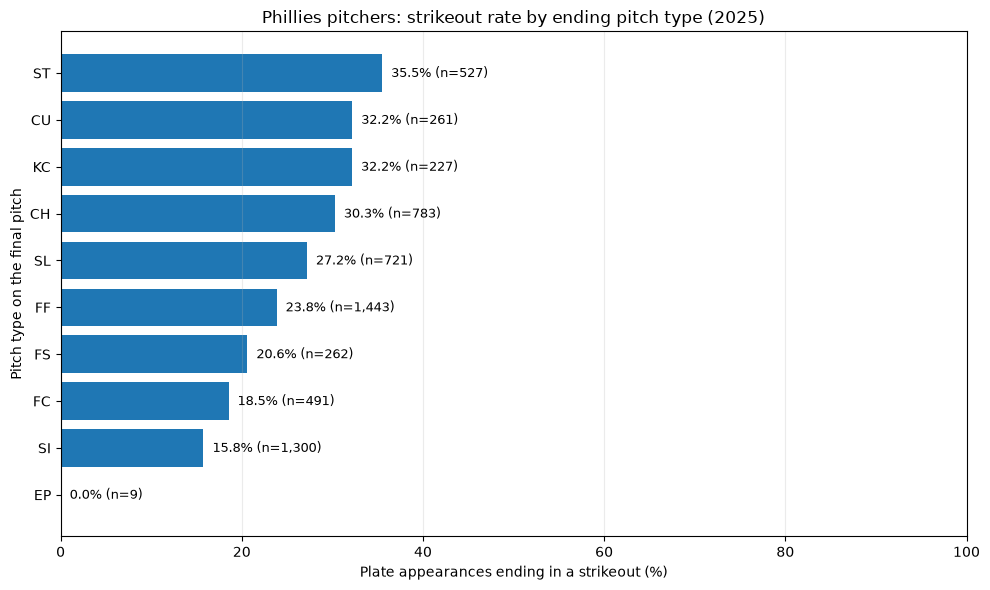

,ending pitch type,plate appearances,strikeout rate
2,EP,9,0.000000
8,SI,1300,0.157692
4,FC,491,0.185336
6,FS,262,0.206107
5,FF,1443,0.238392
9,SL,721,0.271845
0,CH,783,0.302682
7,KC,227,0.321586
1,CU,261,0.321839
10,ST,527,0.354839


In [ ]:
terminal_pitch_rows = (
    labeled_pitches.sort_values(pitch_order)
    .groupby(pa_keys, sort=False, as_index=False)
    .tail(1)
    .copy()
)
terminal_pitch_rows["pitch_type"] = terminal_pitch_rows["pitch_type"].fillna("Unknown")

by_pitch_type = (
    terminal_pitch_rows.groupby("pitch_type", as_index=False)
    .agg(plate_appearances=("strikeout", "size"), strikeout_rate=("strikeout", "mean"))
    .sort_values("plate_appearances", ascending=False)
    .head(10)
    .sort_values("strikeout_rate")
)

if by_pitch_type.empty:
    raise RuntimeError("There are no terminal pitch types available to chart.")

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(by_pitch_type["pitch_type"], by_pitch_type["strikeout_rate"] * 100)
ax.set_xlabel("Plate appearances ending in a strikeout (%)")
ax.set_ylabel("Pitch type on the final pitch")
ax.set_title(f"Phillies pitchers: strikeout rate by ending pitch type ({season})")
ax.set_xlim(0, 100)
ax.grid(axis="x", alpha=0.25)
for bar, count in zip(bars, by_pitch_type["plate_appearances"]):
    ax.text(
        bar.get_width() + 1,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.1f}% (n={count:,})",
        va="center",
        fontsize=9,
    )
fig.tight_layout()
plt.show()

display(by_pitch_type.rename(columns={
    "pitch_type": "ending pitch type",
    "plate_appearances": "plate appearances",
    "strikeout_rate": "strikeout rate"
}))

## 9. Short summary and what this can tell us

The process requested pitch-level Statcast data for Phillies games, selected the pitches thrown by Phillies pitchers, labeled every pitch with its plate appearance's final outcome, kept a focused set of pitch and location measurements, checked counts and broad value ranges, and charted strikeout rates by ending pitch type. The printed counts and chart above are the results for the selected season and the data returned when the notebook is run.

This is a useful prepared dataset, but the chart alone cannot answer whether we can predict strikeouts from pitch characteristics and location. The next step would be to train a statistical or machine-learning model and test it on different games or a later time period than the training data. Splitting by plate appearance (and preferably by game or time) avoids putting pitches from the same appearance in both training and test data. Prediction testing also needs to avoid using the final-pitch result or any information only known after the pitch as an input. Statcast data can have missing measurements and recording limitations, so those need attention in a full modeling analysis.

## 10. Export the expanded data

Run the final code cell after the notebook finishes to create `phillies_pitch_data_enriched.csv`. This keeps the original CSV unchanged and includes pitcher, opponent, and at-bat result fields for the dashboard.

In [ ]:
cleaned.to_csv("phillies_pitch_data_enriched.csv", index=False, na_rep=r"\N")